<a href="https://colab.research.google.com/github/CanopySimulations/canopy-python-examples/blob/master/plot_fastest_laps_from_study.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Plot the Fastest Laps from a Study

Given the id of a study containing multiple jobs (for example an exploration), this notebook:

1. Loads the aggregated scalar results for **every** job in the study, which is a single fast download.
2. Ranks the jobs by `tLapTotal`, smallest (fastest) to largest.
3. Downloads the vector results (`sRun` and `vCar`) for **only** the `n_fastest` quickest jobs.
4. Plots `vCar` against `sRun`, one line per job.
5. Prints a table containing the rank, job index and lap time of each job, along with the exploration settings that were used to run it.

# Upgrade Runtime
This cell ensures the runtime supports `asyncio` async/await, and is needed on Google Colab. If the runtime is upgraded, you will be prompted to restart it, which you should do before continuing execution.

In [1]:
%pip install ipython ipykernel --upgrade

   ---------------------------------------- 0.0/649.8 kB ? eta -:--:--
   ---------------------------------------- 649.8/649.8 kB 6.3 MB/s  0:00:00
   ---------------------------------------- 0.0/535.8 kB ? eta -:--:--
   ---------------------------------------- 535.8/535.8 kB 8.8 MB/s  0:00:00

  Attempting uninstall: tornado

    Found existing installation: tornado 6.5.2

    Uninstalling tornado-6.5.2:

      Successfully uninstalled tornado-6.5.2

   ---------------------------------------- 0/3 [tornado]
   ---------------------------------------- 0/3 [tornado]
   ---------------------------------------- 0/3 [tornado]
   ---------------------------------------- 0/3 [tornado]
   ---------------------------------------- 0/3 [tornado]
   ---------------------------------------- 0/3 [tornado]
   ---------------------------------------- 0/3 [tornado]
   ---------------------------------------- 0/3 [tornado]
   ---------------------------------------- 0/3 [tornado]
   ------------------

  You can safely remove it manually.

[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


# Set Up Environment

### Import required libraries

In [2]:
%pip install -q canopy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import asyncio
import canopy
import logging
import matplotlib.pyplot as plt
import nest_asyncio
import numpy as np
import pandas as pd

logging.basicConfig(level=logging.INFO)
nest_asyncio.apply()

### Authenticate

In [4]:
authentication_data = canopy.prompt_for_authentication()
session = canopy.Session(authentication_data)
session.authentication.authenticate()

# Choose the Study

Set `study_id` to the id of a study containing multiple jobs, and `n_fastest` to the number of jobs you want to plot.

You can find your studies on the Canopy Platform (portal.canopysimulations.com).

If the study ran more than one sim type, set `sim_type` (for example `'DynamicLap'`) to choose which one is ranked and plotted. If it is left as `None` the sim type is detected automatically, which works when only one sim type in the study produced `tLapTotal`.

In [5]:
study_id = '94d91113e62d44a7bec072694d17620e'
n_fastest = 3
sim_type = None

# Load and Rank the Scalar Results

The aggregated scalar results contain one row per job, so we can rank every job in the study without downloading any vector data. As we saw in the [loading scalar results](loading_scalar_results.ipynb) example, the column names are of the form `<Name>:<SimType>`.

In [ ]:
lap_time_channel = 'tLapTotal'

# Note: include_study_scalar_results=True
# We want the scalar results from the _study_, which include the individual job scalar results and
# allow us to find the fastest lap in the study
study = await canopy.load_study(
    session,
    study_id,
    include_study_scalar_results=True)

scalar_results = study.scalar_results
if scalar_results is None or scalar_results.results is None:
    raise RuntimeError(
        f'No aggregated scalar results found for study {study_id}. '
        'This notebook needs a study with multiple jobs which has completed successfully.')

# Work out which sim type we are ranking.
available_sim_types = [
    column.split(':', 1)[1]
    for column in scalar_results.results.columns
    if column.startswith(f'{lap_time_channel}:')]

if sim_type is None:
    if len(available_sim_types) != 1:
        raise ValueError(
            f'Expected exactly one sim type with {lap_time_channel} but found {available_sim_types}. '
            'Please set sim_type explicitly.')
    sim_type = available_sim_types[0]
else:
    sim_type = canopy.ensure_sim_type_string(sim_type)
    if sim_type not in available_sim_types:
        raise ValueError(f'{lap_time_channel} was not found for sim type {sim_type}. Available: {available_sim_types}')

logging.info(f'Study "{study.document.name}" ({study_id}): ranking by {lap_time_channel} for {sim_type}')

# The row index of the scalar results is the job index. Jobs which failed have no lap time, so are dropped.
lap_times = study.scalar_as(f'{lap_time_channel}:{sim_type}', 's').reset_index(drop=True)
ranked_lap_times = lap_times.dropna().sort_values(ascending=True, kind='stable')

logging.info(f'{len(ranked_lap_times)} of {len(lap_times)} jobs have a valid {lap_time_channel}')

n_to_plot = min(n_fastest, len(ranked_lap_times))
if n_to_plot < n_fastest:
    logging.warning(f'Only {n_to_plot} jobs have results, so plotting {n_to_plot} instead of {n_fastest}')

fastest_lap_times = ranked_lap_times.iloc[:n_to_plot]
fastest_job_indices = fastest_lap_times.index.tolist()

fastest_lap_times.rename(f'{lap_time_channel} (s)').to_frame()

INFO:root:Study "Correlation 01-star" (94d91113e62d44a7bec072694d17620e): ranking by tLapTotal for DynamicLap
INFO:root:15 of 15 jobs have a valid tLapTotal


,tLapTotal (s)
2,113.618284
9,113.824120
8,113.827975


# Load the Vector Results for the Fastest Jobs Only

We now download `sRun` and `vCar` for just the jobs we selected above, fetching them concurrently. The rest of the jobs in the study are never downloaded.

In [ ]:
channel_names = ['sRun', 'vCar']
semaphore = asyncio.Semaphore(session.default_api_concurrency)

fastest_jobs = await asyncio.gather(*[
    # Now, note that load_study_job loads only the specified channel_names
    # This means we can use "vector_as" to load a specific vector result
    canopy.load_study_job(
        session,
        study_id,
        sim_type,
        channel_names,
        job_index=job_index,
        semaphore=semaphore)
    for job_index in fastest_job_indices])

INFO:canopy.load_study_job:Loading job index 2
INFO:canopy.load_study_job:Loading job index 9
INFO:canopy.load_study_job:Loading job index 8


# Plot the Fastest Laps

One line per job, coloured by rank (the fastest is the darkest). The study and job ids are printed alongside the plot.

Study id: 94d91113e62d44a7bec072694d17620e
Study name: Correlation 01-star
Sim type: DynamicLap

Rank 1: job index 2, job name "Sweep 1 Point 3", job id 94d91113e62d44a7bec072694d17620e-2, tLapTotal 113.618 s
Rank 2: job index 9, job name "Sweep 4 Point 1", job id 94d91113e62d44a7bec072694d17620e-9, tLapTotal 113.824 s
Rank 3: job index 8, job name "Sweep 3 Point 3", job id 94d91113e62d44a7bec072694d17620e-8, tLapTotal 113.828 s


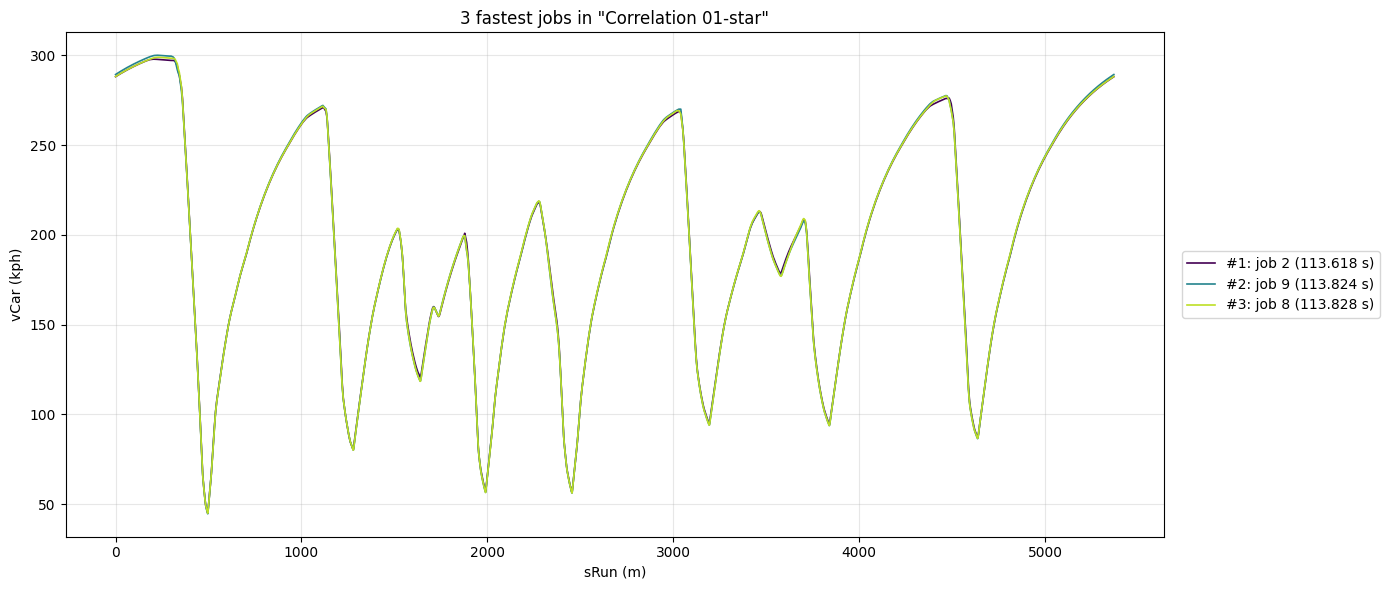

In [8]:
fig, ax = plt.subplots(figsize=(14, 6))
colours = plt.cm.viridis(np.linspace(0, 0.9, len(fastest_jobs)))

print(f'Study id: {study_id}')
print(f'Study name: {study.document.name}')
print(f'Sim type: {sim_type}')
print()

for rank, (job_index, lap_time, job, colour) in enumerate(
        zip(fastest_job_indices, fastest_lap_times, fastest_jobs, colours),
        start=1):

    s_run = job.vector_as('sRun', 'm')
    v_car = job.vector_as('vCar', 'kph')
    if s_run is None or v_car is None:
        raise RuntimeError(f'sRun or vCar was not found for job {job_index}. Loaded channels: {list(job.vector_data.columns)}')

    ax.plot(s_run, v_car, color=colour, lw=1.2, label=f'#{rank}: job {job_index} ({lap_time:.3f} s)')

    print(f'Rank {rank}: job index {job_index}, job name "{job.document.name}", job id {job.document.document_id}, {lap_time_channel} {lap_time:.3f} s')

ax.set_title(f'{n_to_plot} fastest jobs in "{study.document.name}"')
ax.set_xlabel('sRun (m)')
ax.set_ylabel('vCar (kph)')
ax.grid(True, alpha=0.3)
ax.legend(loc='center left', bbox_to_anchor=(1.01, 0.5))
fig.tight_layout()
plt.show()

# Summary Table

The table below lists, for each of the fastest jobs: its rank, the job index (the zero-based job number within the study), the lap time, and the exploration settings which were used to run it. The settings come from the scalar inputs of the study, and are in the units the exploration was defined in.

In [9]:
summary = pd.DataFrame({
    'rank': range(1, n_to_plot + 1),
    'job_index': fastest_job_indices,
    f'{lap_time_channel} (s)': fastest_lap_times.to_numpy(),
})

exploration_settings = scalar_results.inputs
if exploration_settings is not None:
    summary = pd.concat(
        [summary, exploration_settings.loc[fastest_job_indices].reset_index(drop=True)],
        axis=1)

with pd.option_context('display.max_columns', None, 'display.width', 250, 'display.max_colwidth', None):
    print(summary.to_string(index=False))

 rank  job_index  tLapTotal (s)  car.tyres.front.rGripFactor*  car.tyres.rear.rGripFactor*  car.powertrain.engine.rEnginePowerFactor=  car.aero.PolynomialCDragBodyDefinition[0].coefficient+  car.aero.coefficientOffsets.CLiftBodyUserOffset+
    1          2     113.618284                          1.01                          NaN                                        NaN                                                     NaN                                               NaN
    2          9     113.824120                           NaN                          NaN                                        NaN                                                   -0.02                                               NaN
    3          8     113.827975                           NaN                          NaN                                       1.01                                                     NaN                                               NaN
